In [397]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
import numpy as np
from sklearn.model_selection import train_test_split
import re
import matplotlib.pyplot as plt
import seaborn as sns
scaler = StandardScaler()
imputer = SimpleImputer(strategy = 'median')


defensive_pos = ["Defensive Tackle",
  "Nose Tackle",
  "Defensive End",
  "Edge Rusher",
  "Middle Linebacker",
  "Inside Linebacker",
  "Outside Linebacker",
  "Cornerback",
  "Free Safety",
  "Strong Safety",
  "Nickelback",
  "Dimeback"]

offensive_pos = ["Quarterback",
  "Running Back",
  "Fullback",
  "Wide Receiver",
  "Tight End",
  "Center",
  "Left Guard",
  "Right Guard",
  "Left Tackle",
  "Right Tackle",
  "Offensive Guard",
  "Offensive Tackle"]

In [90]:
#read player

player_crr_df = pd.read_csv('./nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/player_career_successes.csv')
player_df = pd.read_csv('./nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/players.csv')
# player_ply_df = pd.read_csv('./nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/player_play.csv')
print('read players')


read players


In [3]:
# read games

games_df = pd.read_csv('./nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/games.csv')
print('read games')

read games


In [4]:
#read games 2023
game_trk_2023_df = pd.read_csv('./nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/game_tracking_2023.csv')
print('read games 2023')


read games 2023


In [5]:
#read games 2024
game_trk_2024_df = pd.read_csv('./nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/game_tracking_2024.csv')
print('read games 2024')


read games 2024


In [6]:
#read games 2025
game_trk_2025_df = pd.read_csv('./nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/game_tracking_2025.csv')
print('read games 2025')

read games 2025


In [7]:
#read combine_res
combine_res_df = pd.read_csv('./nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/combine_results.csv')
print("read combine_res")
mapToOffense = {"WR": "Offense", "TE": "Offense", "OL": "Offense", "DL": "Defense", "DB": "Defense"}

read combine_res


In [103]:
#read combine_trk
combine_trk_df = pd.read_csv('./nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/combine_tracking.csv')
print("read combine_trk")

read combine_trk


In [104]:
#List of all current dfs
dfs = {'combine_res': combine_res_df, 'game_trk_2023': game_trk_2023_df, 'game_trk_2024': game_trk_2024_df, 
       'game_trk_2025': game_trk_2025_df, 'player_crr': player_crr_df, 'player': player_df, 
       'combine_trk': combine_trk_df, 'games': games_df}

combine_trk_df.head()

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir
0,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.200,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.785924,28.285528,0.220828,0.682443,0.011085,250.278576
1,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.300,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.723780,28.297391,0.332931,0.619551,0.003864,257.319206
2,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.400,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.632680,28.279528,0.481838,0.596455,0.008305,253.176813
3,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.500,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.544022,28.243767,0.599350,0.664436,0.007964,247.044153
4,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.600,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.471466,28.210294,0.657540,0.908250,0.005382,240.622668


In [84]:
#player_crr
player_crr_df["career_snaps"] = player_crr_df[
    ["career_offensive_snaps", "career_defensive_snaps"]
].sum(axis=1)

player_crr_df = player_crr_df.drop(
    columns=["career_offensive_snaps", "career_defensive_snaps"]
)

KeyError: "None of [Index(['career_offensive_snaps', 'career_defensive_snaps'], dtype='str')] are in the [columns]"

In [101]:

combine_trk_df = combine_trk_df[
    combine_trk_df['entity_type'] == 'PLAYER'
    ]

In [102]:
combine_trk_df = combine_trk_df.drop(
    columns = ['x', 'y', 'dis', 'dir', 'entity_type']
)

In [106]:

combine_trk_df = combine_trk_df.groupby(
    ['drill_type', 'nfl_id', 'draft_year']).agg(
    max_speed_combinetrk=('s','max'),
    avg_speed_combinetrk=('s', 'mean'),
    max_acceleration_combinetrk=('a','max'),
    avg_acceleration_combinetrk=('a','mean'),
    min_acceleration_combinetrk=('a','min'),
    total_frames_combinetrk = ('s','count'),
    num_attempts=('attempt', 'nunique')
).reset_index()

In [108]:
combine_trk_df = combine_trk_df.groupby(
    ['nfl_id', 'drill_type', 'draft_year']
).agg(
    max_speed_combinetrk=('max_speed_combinetrk', 'max'),
    avg_speed_combinetrk=('avg_speed_combinetrk', 'mean'),

    max_acceleration_combinetrk=('max_acceleration_combinetrk', 'max'),
    avg_acceleration_combinetrk=('avg_acceleration_combinetrk', 'mean'),
    min_acceleration_combinetrk=('min_acceleration_combinetrk', 'min'),

    avg_frames_per_attempt=('total_frames_combinetrk', 'mean'),
    total_frames_combinetrk=('total_frames_combinetrk', 'sum'),
    num_attempts=('num_attempts', 'sum')
).reset_index()

Previously the cell below created a combination of drill type and drill name
this of course created a ginormous number of combinations which made x_train messy
in order to combat this i will instead average within the drill type. The hope this results in much less
columns for x_train

In [109]:
metrics = [
    'max_speed_combinetrk',
    'avg_speed_combinetrk',
    'max_acceleration_combinetrk',
    'avg_acceleration_combinetrk',
    'min_acceleration_combinetrk',
    'avg_frames_per_attempt',
    'total_frames_combinetrk',
    'num_attempts'
]

combine_trk_df = combine_trk_df.pivot(
    index=['nfl_id', 'draft_year'],
    columns=['drill_type'],
    values=metrics
)

combine_trk_df.columns = [
    f'{metric}_{drill_type}'
    for metric, drill_type in combine_trk_df.columns
]

combine_trk_df = combine_trk_df.reset_index()


In [110]:

#==========================================================Begin Cleaning game_[year] ===============================================================
dfs['game_trk_2025'] = dfs['game_trk_2025'][dfs['game_trk_2025']['s'] > 0]
aggr_games_trk2025_df = dfs['game_trk_2025'].groupby(
    ['nfl_id']).agg(
    max_speed=('s','max'),
    avg_speed=('s', 'mean'),
    max_acceleration=('a','max'),
    avg_acceleration=('a','mean'),
    total_frames=('s','count')
).reset_index()


In [111]:
dfs['game_trk_2024'] = dfs['game_trk_2024'][dfs['game_trk_2024']['s'] > 0]
aggr_games_trk2024_df = dfs['game_trk_2024'].groupby(
    ['nfl_id']).agg(
    max_speed=('s','max'),
    avg_speed=('s', 'mean'),
    max_acceleration=('a','max'),
    avg_acceleration=('a','mean'),
    total_frames=('s','count')
).reset_index()


In [112]:
dfs['game_trk_2023'] = dfs['game_trk_2023'][dfs['game_trk_2023']['s'] > 0]
aggr_games_trk2023_df = dfs['game_trk_2023'].groupby(
    ['nfl_id']).agg(
    max_speed=('s','max'),
    avg_speed=('s', 'mean'),
    max_acceleration=('a','max'),
    avg_acceleration=('a','mean'),
    total_frames=('s','count')
).reset_index()

                  

In [113]:
all_aggr_games_trk_df = pd.concat(
    [aggr_games_trk2023_df, aggr_games_trk2024_df, aggr_games_trk2025_df], 
    ignore_index = True
)

#=============================================================================END cleaning game_[year]=================================================

In [114]:
all_aggr_games_trk_df = all_aggr_games_trk_df.groupby(
    ['nfl_id']).agg(
    max_speed=('max_speed','max'),
    avg_speed=('avg_speed', 'mean'),
    max_acceleration=('max_acceleration','max'),
    avg_acceleration=('avg_acceleration','mean'),
    total_frames=('total_frames','sum')
).reset_index()
    

In [115]:
#==================================================== begin clean player csv================================
player_df['Age'] = ((pd.to_datetime(player_df['draft_year'], format='%Y') - pd.to_datetime(player_df['birth_date'])).dt.days / 365.25).astype(int)
player_df = player_df.drop(columns = ['birth_date', 'draft_year'])


In [116]:
#using all game_trk, combine_trk, combine_res, player, player_crr_df
ML_df = pd.merge(all_aggr_games_trk_df, combine_trk_df, on = 'nfl_id')
ML_df = pd.merge(ML_df, combine_res_df, on = 'nfl_id')
ML_df = pd.merge(ML_df, player_df, on = 'nfl_id')
ML_df = pd.merge(ML_df, player_crr_df, on = 'nfl_id')


In [117]:
print(ML_df.columns)

Index(['nfl_id', 'max_speed', 'avg_speed', 'max_acceleration',
       'avg_acceleration', 'total_frames', 'draft_year_x',
       'max_speed_combinetrk_FORTY_YARD_DASH',
       'max_speed_combinetrk_SHORT_SHUTTLE',
       'max_speed_combinetrk_SKILL_DRILLS_DB',
       ...
       'draft_overall_pick', 'Age', 'career_offensive_snaps',
       'career_defensive_snaps', 'career_special_teams_snaps',
       'career_games_active', 'career_games_started', 'ap_all_pro_1st_team',
       'ap_all_pro_2nd_team', 'pro_bowl_original_ballot'],
      dtype='str', length=112)


In [377]:
X = ML_df.drop(columns = ['draft_overall_pick', 'nfl_id'])
y = ML_df['draft_overall_pick']

In [378]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify = ML_df['combine_position']
)

In [385]:
# pd.reset_option('display.max_columns')
# pd.set_option('display.max_columns', None)
# X_train.head()

X_train_by_position = {name: group for name, group in X_train.groupby('combine_position')}
# mapToOffense = {"WR": "Offense", "TE": "Offense", "OL": "Offense", 
                # "DL": "Defense", "DB": "Defense"}


Moving forward with the idea that each player has only ONE draft year. We should inspect the data to see
if this is false. if so we should average their age over the draft years i think

In [386]:
pd.set_option('display.max_columns', None)
# check if multiple ids
# check if 
X_train_by_position['WR'].loc[X_train_by_position['WR']['draft_year_x'].duplicated(keep=False)].head()

,max_speed,avg_speed,max_acceleration,avg_acceleration,total_frames,draft_year_x,max_speed_combinetrk_FORTY_YARD_DASH,max_speed_combinetrk_SHORT_SHUTTLE,max_speed_combinetrk_SKILL_DRILLS_DB,max_speed_combinetrk_SKILL_DRILLS_DL,max_speed_combinetrk_SKILL_DRILLS_LB,max_speed_combinetrk_SKILL_DRILLS_OL,max_speed_combinetrk_SKILL_DRILLS_TE,max_speed_combinetrk_SKILL_DRILLS_WR,max_speed_combinetrk_THREE_CONE_DRILL,avg_speed_combinetrk_FORTY_YARD_DASH,avg_speed_combinetrk_SHORT_SHUTTLE,avg_speed_combinetrk_SKILL_DRILLS_DB,avg_speed_combinetrk_SKILL_DRILLS_DL,avg_speed_combinetrk_SKILL_DRILLS_LB,avg_speed_combinetrk_SKILL_DRILLS_OL,avg_speed_combinetrk_SKILL_DRILLS_TE,avg_speed_combinetrk_SKILL_DRILLS_WR,avg_speed_combinetrk_THREE_CONE_DRILL,max_acceleration_combinetrk_FORTY_YARD_DASH,max_acceleration_combinetrk_SHORT_SHUTTLE,max_acceleration_combinetrk_SKILL_DRILLS_DB,max_acceleration_combinetrk_SKILL_DRILLS_DL,max_acceleration_combinetrk_SKILL_DRILLS_LB,max_acceleration_combinetrk_SKILL_DRILLS_OL,max_acceleration_combinetrk_SKILL_DRILLS_TE,max_acceleration_combinetrk_SKILL_DRILLS_WR,max_acceleration_combinetrk_THREE_CONE_DRILL,avg_acceleration_combinetrk_FORTY_YARD_DASH,avg_acceleration_combinetrk_SHORT_SHUTTLE,avg_acceleration_combinetrk_SKILL_DRILLS_DB,avg_acceleration_combinetrk_SKILL_DRILLS_DL,avg_acceleration_combinetrk_SKILL_DRILLS_LB,avg_acceleration_combinetrk_SKILL_DRILLS_OL,avg_acceleration_combinetrk_SKILL_DRILLS_TE,avg_acceleration_combinetrk_SKILL_DRILLS_WR,avg_acceleration_combinetrk_THREE_CONE_DRILL,min_acceleration_combinetrk_FORTY_YARD_DASH,min_acceleration_combinetrk_SHORT_SHUTTLE,min_acceleration_combinetrk_SKILL_DRILLS_DB,min_acceleration_combinetrk_SKILL_DRILLS_DL,min_acceleration_combinetrk_SKILL_DRILLS_LB,min_acceleration_combinetrk_SKILL_DRILLS_OL,min_acceleration_combinetrk_SKILL_DRILLS_TE,min_acceleration_combinetrk_SKILL_DRILLS_WR,min_acceleration_combinetrk_THREE_CONE_DRILL,avg_frames_per_attempt_FORTY_YARD_DASH,avg_frames_per_attempt_SHORT_SHUTTLE,avg_frames_per_attempt_SKILL_DRILLS_DB,avg_frames_per_attempt_SKILL_DRILLS_DL,avg_frames_per_attempt_SKILL_DRILLS_LB,avg_frames_per_attempt_SKILL_DRILLS_OL,avg_frames_per_attempt_SKILL_DRILLS_TE,avg_frames_per_attempt_SKILL_DRILLS_WR,avg_frames_per_attempt_THREE_CONE_DRILL,total_frames_combinetrk_FORTY_YARD_DASH,total_frames_combinetrk_SHORT_SHUTTLE,total_frames_combinetrk_SKILL_DRILLS_DB,total_frames_combinetrk_SKILL_DRILLS_DL,total_frames_combinetrk_SKILL_DRILLS_LB,total_frames_combinetrk_SKILL_DRILLS_OL,total_frames_combinetrk_SKILL_DRILLS_TE,total_frames_combinetrk_SKILL_DRILLS_WR,total_frames_combinetrk_THREE_CONE_DRILL,num_attempts_FORTY_YARD_DASH,num_attempts_SHORT_SHUTTLE,num_attempts_SKILL_DRILLS_DB,num_attempts_SKILL_DRILLS_DL,num_attempts_SKILL_DRILLS_LB,num_attempts_SKILL_DRILLS_OL,num_attempts_SKILL_DRILLS_TE,num_attempts_SKILL_DRILLS_WR,num_attempts_THREE_CONE_DRILL,draft_year_y,combine_position,combine_height,combine_weight,hand_size,arm_length,wing_span,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps,ngs_athleticism_score,ngs_college_production_score,ngs_final_score,display_name,nfl_position,college_name,college_conference,draft_round,draft_pick_within_round,Age,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started,ap_all_pro_1st_team,ap_all_pro_2nd_team,pro_bowl_original_ballot
97,10.01,4.122261,15.60,2.429840,77601,2023,11.310000,6.323333,NaN,NaN,NaN,NaN,NaN,10.430000,NaN,8.324209,3.166190,NaN,NaN,NaN,NaN,NaN,5.921833,NaN,6.310022,8.614921,NaN,NaN,NaN,NaN,NaN,8.096933,NaN,2.200805,4.650152,NaN,NaN,NaN,NaN,NaN,3.086346,NaN,0.184872,0.503201,NaN,NaN,NaN,NaN,NaN,0.118228,NaN,99.0,49.0,NaN,NaN,NaN,NaN,NaN,782.0,NaN,99.0,49.0,NaN,NaN,NaN,NaN,NaN,782.0,NaN,2.0,1.0,NaN,NaN,NaN,NaN,NaN,2.0,NaN,2023,WR,68.250,179,8.750,30.250,72.500,1.54,4.44,39.5,134.0,NaN,4.29,NaN,72,63.0,66.0,Demario Douglas,WR,Liberty,Independent,6.0,33.0,22,1448,0,35,51,14,0,0,0
115,10.05,4.000

In [387]:
#remove draft_year x and y

for key, val in X_train_by_position.items():
    X_train_by_position[key] = val.drop(columns = ['draft_year_y', 'draft_year_x'])

In [388]:
skill_drill_cols = X_train_by_position['WR'].filter(regex=r'SKILL_DRILLS_').columns.tolist()
for key, val in X_train_by_position.items():
    combine_posi = X_train_by_position[key]['combine_position'].unique().tolist()[0]
    to_match = "SKILL_DRILLS_" + combine_posi
    for i in skill_drill_cols:
        if to_match in i:
            new_name = re.sub(r'_[A-Za-z]*$', '', i)
            X_train_by_position[key] = X_train_by_position[key].rename(columns={i:new_name})
            continue
        X_train_by_position[key] = X_train_by_position[key].drop(columns = i)
        

In [389]:
for key, val in X_train_by_position.items():
    NaNCols = X_train_by_position[key].columns[X_train_by_position[key].isna().sum() >= 1].tolist()
    X_train_by_position[key][NaNCols] = imputer.fit_transform(X_train_by_position[key][NaNCols])
    num_cols = X_train_by_position[key].select_dtypes(include="number").columns.tolist()
    
    ct = ColumnTransformer(
    transformers=[
        ('', StandardScaler(), num_cols)
    ], 
    remainder='passthrough',
    verbose_feature_names_out=False
    )
    
    ct.set_output(transform="pandas")
    val = ct.fit_transform(X_train_by_position[key])
    X_train_by_position[key] = val
    X_train_by_position[key] = val.drop(columns = ['college_name', 'display_name'])
    # str_cols = X_train_by_position[key].drop(columns = ['nfl_id']).select_dtypes(include="string").columns.tolist()
    # val = pd.get_dummies(X_train_by_position[key], columns=str_cols, drop_first=True, dtype=int)
    # X_train_by_position[key] = val

In [390]:
fin_X_train = pd.concat(
    X_train_by_position, 
    ignore_index = True
)

In [392]:
str_cols = fin_X_train.select_dtypes(include = 'string').columns.tolist()
val = pd.get_dummies(fin_X_train, columns=str_cols, drop_first=True, dtype=int)
fin_X_train = val

In [344]:
nfl_cols = fin_X_train.filter(regex=r'nfl_position').columns.tolist()

fin_X_train = fin_X_train.drop(columns = nfl_cols)

In [395]:
fin_X_train.head()

,max_speed,avg_speed,max_acceleration,avg_acceleration,total_frames,max_speed_combinetrk_FORTY_YARD_DASH,max_speed_combinetrk_SHORT_SHUTTLE,max_speed_combinetrk_SKILL_DRILLS,max_speed_combinetrk_THREE_CONE_DRILL,avg_speed_combinetrk_FORTY_YARD_DASH,avg_speed_combinetrk_SHORT_SHUTTLE,avg_speed_combinetrk_SKILL_DRILLS,avg_speed_combinetrk_THREE_CONE_DRILL,max_acceleration_combinetrk_FORTY_YARD_DASH,max_acceleration_combinetrk_SHORT_SHUTTLE,max_acceleration_combinetrk_SKILL_DRILLS,max_acceleration_combinetrk_THREE_CONE_DRILL,avg_acceleration_combinetrk_FORTY_YARD_DASH,avg_acceleration_combinetrk_SHORT_SHUTTLE,avg_acceleration_combinetrk_SKILL_DRILLS,avg_acceleration_combinetrk_THREE_CONE_DRILL,min_acceleration_combinetrk_FORTY_YARD_DASH,min_acceleration_combinetrk_SHORT_SHUTTLE,min_acceleration_combinetrk_SKILL_DRILLS,min_acceleration_combinetrk_THREE_CONE_DRILL,avg_frames_per_attempt_FORTY_YARD_DASH,avg_frames_per_attempt_SHORT_SHUTTLE,avg_frames_per_attempt_SKILL_DRILLS,avg_frames_per_attempt_THREE_CONE_DRILL,total_frames_combinetrk_FORTY_YARD_DASH,total_frames_combinetrk_SHORT_SHUTTLE,total_frames_combinetrk_SKILL_DRILLS,total_frames_combinetrk_THREE_CONE_DRILL,num_attempts_FORTY_YARD_DASH,num_attempts_SHORT_SHUTTLE,num_attempts_SKILL_DRILLS,num_attempts_THREE_CONE_DRILL,combine_height,combine_weight,hand_size,arm_length,wing_span,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps,ngs_athleticism_score,ngs_college_production_score,ngs_final_score,draft_round,draft_pick_within_round,Age,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started,ap_all_pro_1st_team,ap_all_pro_2nd_team,pro_bowl_original_ballot,combine_position_DL,combine_position_OL,combine_position_TE,combine_position_WR,nfl_position_CB,nfl_position_DB,nfl_position_DE,nfl_position_DT,nfl_position_FS,nfl_position_G,nfl_position_ILB,nfl_position_MLB,nfl_position_NT,nfl_position_OLB,nfl_position_SS,nfl_position_T,nfl_position_TE,nfl_position_WR,college_conference_Atlantic Coast Conference,college_conference_Big South - Ohio Valley Conference,college_conference_Big Ten Conference,college_conference_Big Twelve Conference,college_conference_Conference USA,college_conference_Independent,college_conference_Ivy League,college_conference_Mid-American Conference,college_conference_Missouri Valley Football Conference,college_conference_Mountain West Conference,college_conference_Pacific Twelve Conference,college_conference_Patriot League,college_conference_Southeastern Conference,college_conference_Southwestern Athletic Conference,college_conference_Sun Belt Conference
0,-0.364804,-0.252045,-0.510363,0.290331,-0.258429,-0.018985,-3.350810,-1.021574,-0.013438,0.120136,-1.084572,-1.550610,-0.14867,-0.120138,-4.450919,-1.406634,0.017809,0.081263,-0.736396,-2.431121,-0.172225,-0.080807,3.736180,-1.456630,-0.010347,0.215786,0.001266,-0.940646,-0.177842,0.215786,0.001266,-0.940646,-0.177842,0.325396,-0.237023,-0.618821,-0.181568,-0.668740,-1.087578,-0.599742,-0.050601,-0.145031,0.119323,-0.066984,-0.551349,-0.696308,0.008152,0.806726,-1.629389,-1.731201,-0.753061,-1.693984,0.088278,0.070977,0.969671,0.0,-0.222564,0.829210,0.690277,-0.456425,-0.103695,0.0,-0.103695,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
1,-0.364804,0.090768,-0.798674,0.510531,-0.851641,-0.018985,0.079646,-0.952503,-0.013438,0.120136,0.110035,0.206981,-0.14867,-0.120138,0.015583,0.899431,0.017809,0.081263,0.120531,-0.108086,-0.172225,-0.080807,-0.142126,-1.042712,-0.010347,0.215786,-0.197125,-0.233167,-0.177842,0.215786,-0.197125,-0.233167,-0.177842,0.325396,-0.237023,-0.618821,-0.181568,-0.586136,-1.185690,-0.849192,-0.843344,-1.876189,0.119323,-0.066984,0.073070,-0.123833,0.008152,0.144114,-0.052716,-1.731201,-0.315199,-1.855316,0.088278,0.070977,-0.066114,0.0,-0.861697,-0.892230,-1.318391,-0.745017,-0.103695,0.0,-0.103695,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
2,-0.819835,0.197788,

In [396]:
fin_X_train.shape

(397, 96)

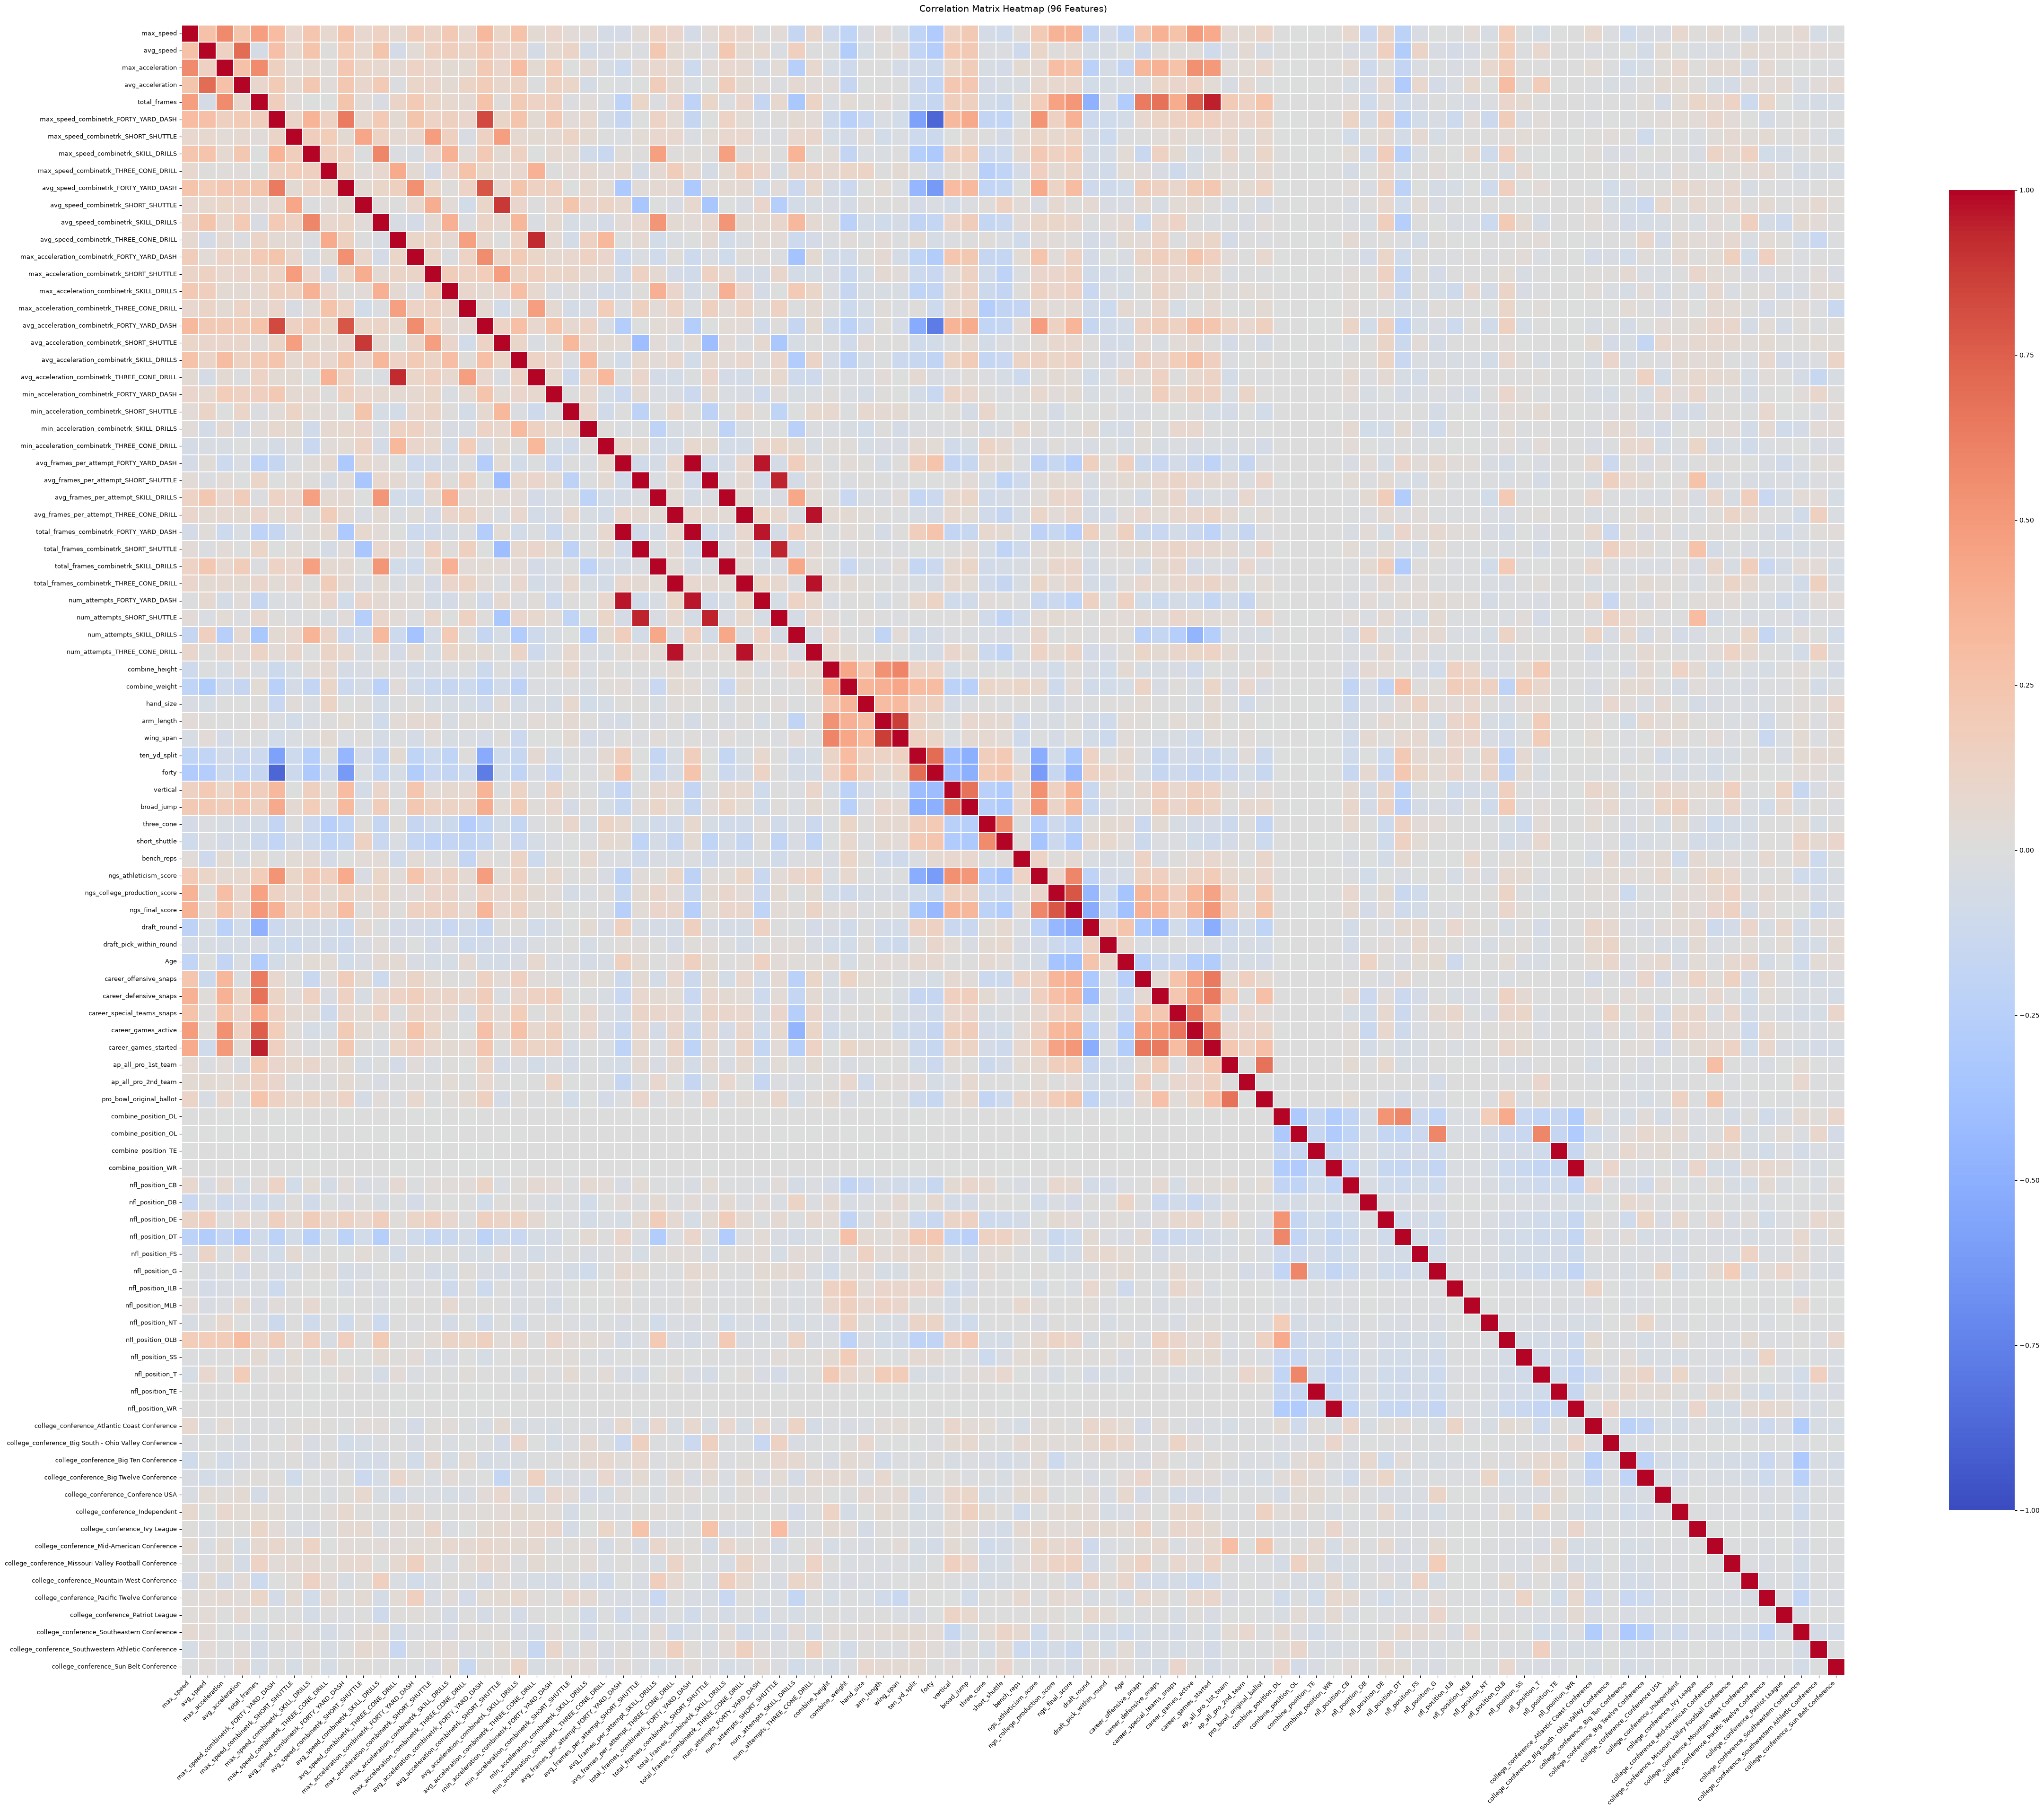

In [399]:

corr_matrix = fin_X_train.corr()

num_features = len(fin_X_train.columns)
fig_width = max(12, num_features * 0.5)
fig_height = max(10, num_features * 0.4)

plt.figure(figsize=(fig_width, fig_height))

sns.heatmap(
    corr_matrix,
    annot=num_features < 30,  
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.1, 
    vmin=-1,
    vmax=1,
    cbar_kws={"shrink": 0.8},  
    annot_kws={"size": 8}, 
)

plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.title(f"Correlation Matrix Heatmap ({num_features} Features)", fontsize=14, pad=20)
plt.tight_layout()

plt.savefig("large_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()